Офлайн-пересчёт сохранённого снимка. Новых агентов и сети нет. Метрики пересчитываются по зафиксированным попыткам; графики сохранённого снимка показаны ниже. Изменение исходных хешей останавливает пересчёт.

In [1]:
import sys
from pathlib import Path
from IPython.display import display, Image, Markdown
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'scripts/report_fipi_extension.py').is_file())
sys.path.insert(0, str(root / 'scripts'))
import report_fipi_extension as report
data = report.collect(50, strict=False, active_snapshot=root / 'data/annotation/runs/2026-11-02-fipi-extension-150/active-scopes/first-050-603ec8fe8e05fe2d.json')
assert data['input_digest'] == '1d5d983a6c18041f74a88e982f509a421b4941083d3f1d2a4c2eb54a6551fcbe', 'Saved inputs changed: use the code version recorded for this snapshot'
summary, tables = report.metrics(data)
report_path = root / 'data/annotation/runs/2026-11-02-fipi-extension-150/derived/checkpoint-100-v1'
if not report_path.exists():
    report_path = report_path.with_name(report_path.name + '.building')


Baseline and frozen inputs byte-identical.


In [2]:
lines = ['| Слой | Отобрано | Завершено | В основных частотах | Узлов каталога с подтверждениями |', '|---|---:|---:|---:|---:|']
for key, name in [('baseline50','Исходные 50: редакторские связи'), ('new_latest50','Последние 50 новых'), ('new_accumulated','Все новые: агентный аудит'), ('mixed_cumulative','Смешанный накопленный корпус')]:
    s = summary[key]
    lines.append(f"| {name} | {s['selected_n']} | {s['complete_n']} | {s['included_n']} | {s['confirmed_catalog_nodes']} |")
display(Markdown('\n'.join(lines)))


| Слой | Отобрано | Завершено | В основных частотах | Узлов каталога с подтверждениями |
|---|---:|---:|---:|---:|
| Исходные 50: редакторские связи | 50 | 50 | 49 | 136 |
| Последние 50 новых | 50 | 50 | 49 | 48 |
| Все новые: агентный аудит | 50 | 50 | 49 | 48 |
| Смешанный накопленный корпус | 100 | 100 | 98 | 138 |

In [3]:
summary['new_accumulated']

{'selected_n': 50,
 'author_n': 50,
 'complete_n': 50,
 'included_n': 49,
 'solution_statuses': {'solved': 50},
 'author_modes': {'standalone_initial': 49, 'source_reading_feedback': 1},
 'excluded': [{'task_id': 'C41083', 'reasons': ['blocking_audit_issue']}],
 'audit_statuses': {'match': {'numerator': 87, 'denominator': 199},
  'new_candidate': {'numerator': 62, 'denominator': 199},
  'needs_split': {'numerator': 41, 'denominator': 199},
  'uncertain': {'numerator': 9, 'denominator': 199}},
 'blocking_tasks': 1,
 'confirmed_catalog_nodes': 48,
 'singleton_nodes': {'numerator': 30, 'denominator': 48},
 'incomplete_mapping_tasks': 45,
 'unmatched_local_candidates': {'numerator': 110, 'denominator': 197},
 'structure': {'all': {'steps': {'n': 49,
    'median': 4,
    'distribution': {1: 1, 2: 12, 3: 9, 4: 10, 5: 12, 6: 4, 7: 1}},
   'kc_candidates': {'n': 49,
    'median': 4,
    'distribution': {1: 1, 2: 11, 3: 6, 4: 12, 5: 11, 6: 4, 7: 3, 8: 1}},
   'methods': {'n': 49,
    'median': 

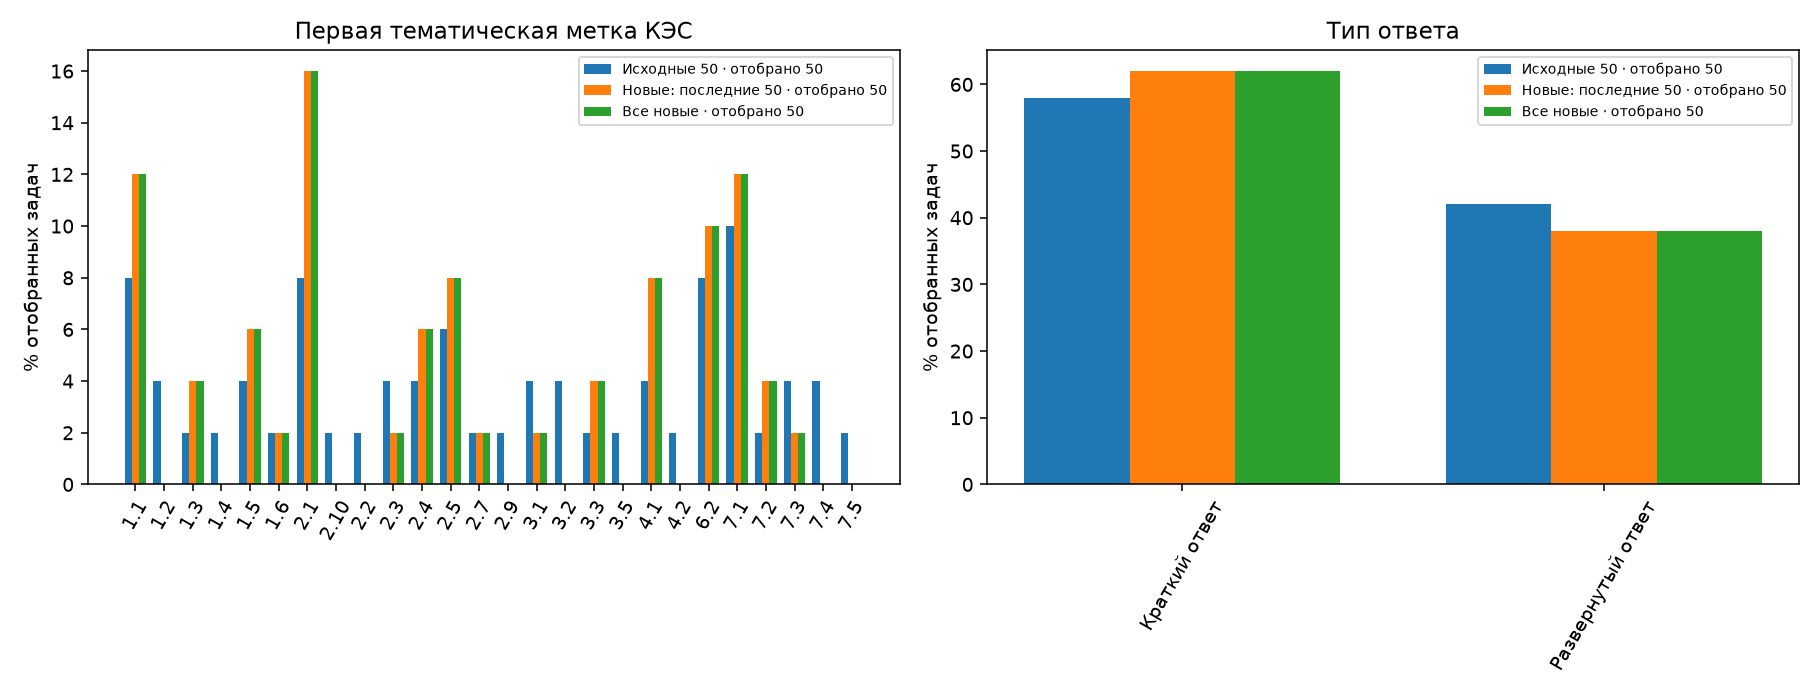

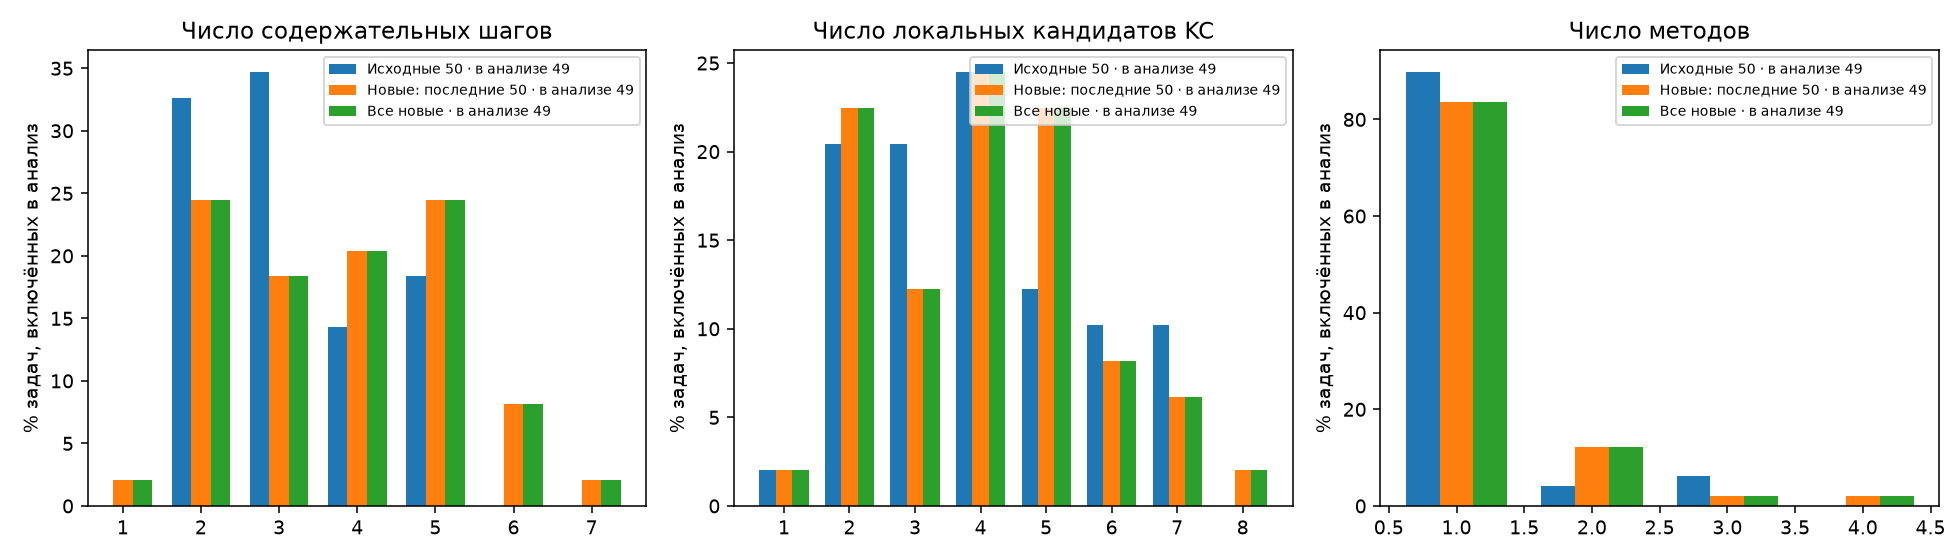

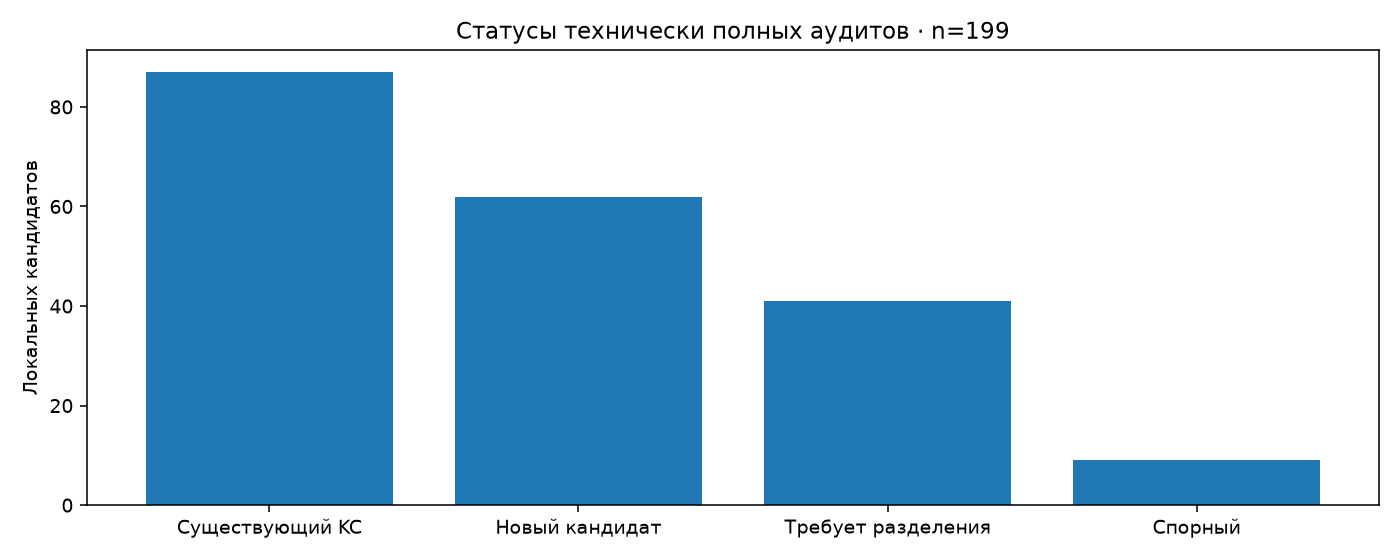

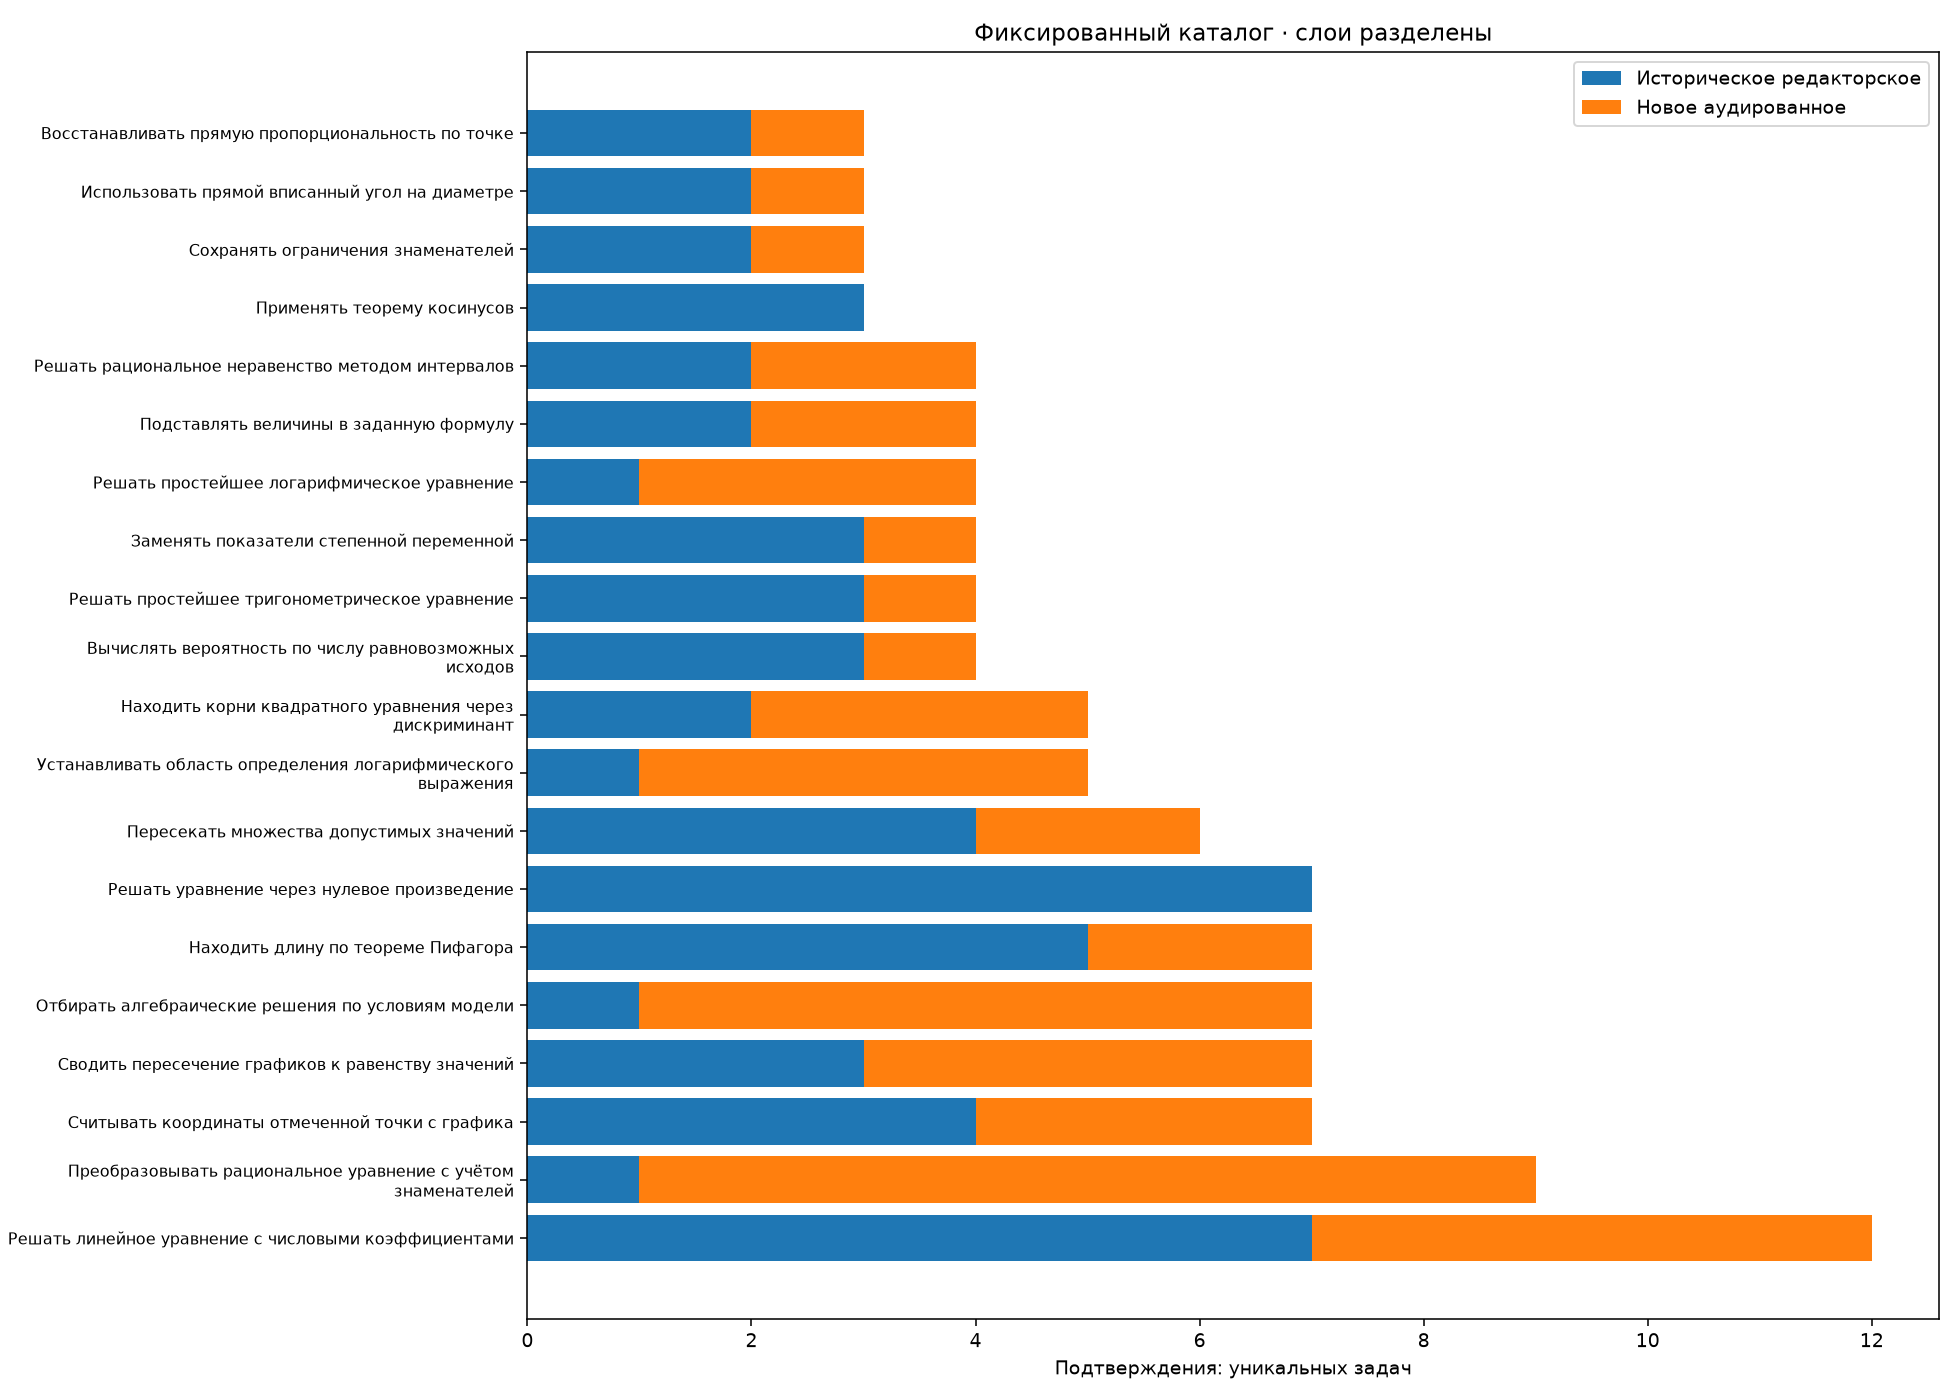

In [4]:
for name in ['01-composition.png','02-structure.png','03-audit-statuses.png','04-catalog-evidence.png']:
    display(Image(filename=str(report_path / name)))
